In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, glob, re
import matplotlib as mpl
import xarray as xr
from matplotlib.colors import BoundaryNorm
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
plt.rcParams.update({
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlesize": 14
})

In [2]:
def clean_dataframe(df, N): #for aeronet data downloads, and to remove the last N columns as well as the ones with nan (given as -999)
    df["datetime"] = pd.to_datetime(
        df["Date(dd:mm:yyyy)"] + " " + df["Time(hh:mm:ss)"],
        format="%d:%m:%Y %H:%M:%S"
    )
    df.drop(columns=["Date(dd:mm:yyyy)", "Time(hh:mm:ss)", "Day_of_Year(Fraction)"], inplace=True)
    df = df[["datetime"] + [col for col in df.columns if col != "datetime"]]
    df.drop(df.columns[-N:], axis=1, inplace=True)
    numeric_cols = df.select_dtypes(include="number")
    cols_to_drop = numeric_cols.columns[(numeric_cols < -900).all()]
    df.drop(columns=cols_to_drop, inplace=True)
    df = df.replace(-999.0, np.nan)
    return df

In [3]:
def rename_ssa_columns(df):   #name grasp columns as SSA_wl
    rename_dict = {}
 
    for col in df.columns:
        col_lower = col.lower()
 
        # Check that it is an SSA column
        if "ssa" in col_lower or "single_scattering_albedo" in col_lower:
 
            # Check the wavelength
            for wl in range(320, 361, 10):
                if f"0.{wl}" in col_lower:
                    rename_dict[col] = f"SSA_{wl}"
                    break
 
    return df.rename(columns=rename_dict)

In [4]:
def rename_aod_columns(df):   #name grasp columns as SSA_wl
    rename_dict = {}
 
    for col in df.columns:
        col_lower = col.lower()
 
        # Check that it is an SSA column
        if "aod" in col_lower or "optical_depth" in col_lower:
 
            # Check the wavelength
            for wl in range(320, 361, 10):
                if f"0.{wl}" in col_lower:
                    rename_dict[col] = f"AOD_{wl}"
                    break
 
    return df.rename(columns=rename_dict)

In [5]:
def nc_to_df(file, range="UV"): #Either UV or UVIS

    # Open the NetCDF with xarray
    ds = xr.open_dataset(file)

    # Convert dates to pandas datetime format
    dates = pd.to_datetime(ds['Day'].values)

    # Read optical properties (dimensions: Day, B_mono)
    GEXT = ds['GEXT'].values
    GSCA = ds['GSCA'].values
    GASY = ds['GASY'].values

    ds.close()

    # Calculate single scattering albedo (scattering / extinction)
    SSA = np.divide(GSCA, GEXT, out=np.full_like(GSCA, np.nan),
                    where=GEXT != 0)

    # Convert wavelengths from microns to nm for column names
    if range == "UV":
        wvls_nm = [320, 330, 340, 350, 360]
    else:  # UVIS
        wvls_nm = [320, 330, 340, 350, 360, 440, 675, 870]

    # Create DataFrame
    data = {'date': dates}

    for i, wvl in enumerate(wvls_nm):
        data[f'AOD_{wvl}'] = GEXT[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'SSA_{wvl}'] = SSA[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'asym_{wvl}'] = GASY[:, i]

    return pd.DataFrame(data)

In [6]:
def nc_to_df_DB19(file): #Special for DB19 wvls (+380nm)

    # Open the NetCDF with xarray
    ds = xr.open_dataset(file)

    # Convert dates to pandas datetime format
    dates = pd.to_datetime(ds['Day'].values)

    # Read optical properties (dimensions: Day, B_mono)
    GEXT = ds['GEXT'].values
    GSCA = ds['GSCA'].values
    GASY = ds['GASY'].values

    ds.close()

    # Calculate single scattering albedo (scattering / extinction)
    SSA = np.divide(GSCA, GEXT, out=np.full_like(GSCA, np.nan),
                    where=GEXT != 0)

    # Convert wavelengths from microns to nm for column names
    wvls_nm = [0.370, 0.380, 0.470, 0.520, 0.590, 0.660, 0.880, 0.950]

    # Create DataFrame
    data = {'date': dates}

    for i, wvl in enumerate(wvls_nm):
        data[f'AOD_{wvl}'] = GEXT[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'SSA_{wvl}'] = SSA[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'asym_{wvl}'] = GASY[:, i]

    return pd.DataFrame(data)

In [7]:
def nc_to_df_extended(file): #Special for DB19 wvls (+380nm)

    # Open the NetCDF with xarray
    ds = xr.open_dataset(file)

    # Convert dates to pandas datetime format
    dates = pd.to_datetime(ds['Day'].values)

    # Read optical properties (dimensions: Day, B_mono)
    GEXT = ds['GEXT'].values
    GSCA = ds['GSCA'].values
    GASY = ds['GASY'].values

    ds.close()

    # Calculate single scattering albedo (scattering / extinction)
    SSA = np.divide(GSCA, GEXT, out=np.full_like(GSCA, np.nan),
                    where=GEXT != 0)

    # Convert wavelengths from microns to nm for column names
    wvls_nm = [0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.44, 0.52, 0.675, 0.87]

    # Create DataFrame
    data = {'date': dates}

    for i, wvl in enumerate(wvls_nm):
        data[f'AOD_{wvl}'] = GEXT[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'SSA_{wvl}'] = SSA[:, i]

    for i, wvl in enumerate(wvls_nm):
        data[f'asym_{wvl}'] = GASY[:, i]

    return pd.DataFrame(data)

In [8]:
#GRASP results:

#all_grasp = pd.read_csv(r"C:\Users\Usuario\Desktop\BSC_secondment\GHI+AOD_multi.csv") #blue
all_grasp = pd.read_csv("climatology_grasp_thess.csv") #blue
comparison = pd.read_csv("climatology_grasp_thess.csv") #orange

all_grasp["datetime"] = pd.to_datetime(all_grasp["datetime"])
comparison["datetime"] = pd.to_datetime(comparison["datetime"])

all_grasp = rename_ssa_columns(all_grasp)
comparison = rename_ssa_columns(comparison)

all_grasp = all_grasp.loc[all_grasp["residual_relative_noise0"]<=0.3]

In [9]:
#Lets filter by rel err of the RADIANCE (noise 0) and delete the retrievals over 68.5
rel_err = 0.06
grasp = all_grasp.loc[all_grasp["residual_relative_noise0"]<rel_err]
#We first only want to see how many retrievals fullfil the error threshold
print(f"Total amount of results: {len(all_grasp)}")
print(f"Amount of points after the {rel_err}, filtering: {len(grasp)}, ({len(grasp)/len(all_grasp)*100})")
#grasp = grasp.loc[grasp["sza"]<=68.5]

Total amount of results: 85
Amount of points after the 0.06, filtering: 85, (100.0)


In [10]:
comp = comparison.loc[comparison["residual_relative_noise0"]<rel_err]
#We first only want to see how many retrievals fullfil the error threshold
print(f"Total amount of results: {len(comparison)}")
print(f"Amount of points after the {rel_err}, filtering: {len(comp)}, ({len(comp)/len(comparison)*100})")

Total amount of results: 85
Amount of points after the 0.06, filtering: 85, (100.0)


In [11]:
aeronet_aod = pd.read_csv("20100601_20241231_Thessaloniki.lev20", skiprows=6)
data = clean_dataframe(aeronet_aod,33) 
inversions = pd.read_csv("AERONET_SSA_Thessaloniki.ssa", skiprows=6)
aeronet_ssa = clean_dataframe(inversions,33)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_5716\2796597115.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(df.columns[-N:], axis=1, inplace=True)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_5716\2796597115.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=cols_to_drop, inplace=True)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_5716\2796597115.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dr

In [12]:
#Now lets filter AERONET data by dates from our results csv
#To keep only the days studied in this csv
dust_days = grasp['datetime'].dt.date

# Filter AERONET data by the grasp retrievals abailability 
data = data[data['datetime'].dt.date.isin(dust_days)]
data = data.reset_index(drop=True)
aeronet_ssa = aeronet_ssa[aeronet_ssa['datetime'].dt.date.isin(dust_days)]
aeronet_ssa = aeronet_ssa.reset_index(drop=True)
#Lets take only the visible wvl SSA:
aeronet_mean = aeronet_ssa.iloc[:,3:6].mean().values
aeronet_std  = aeronet_ssa.iloc[:,3:6].std().values  

In [13]:
#Merge GRASP + AERONET mean and std (2011-2023)

WL =[440,675,870]
WL_uv = np.linspace(320, 360, 5)
ssa_cols = ["SSA_320", "SSA_330", "SSA_340", "SSA_350", "SSA_360", "SSA_440", "SSA_675", "SSA_870"]

ssa_mean = grasp[ssa_cols[:5]].mean().values
ssa_std  = grasp[ssa_cols[:5]].std().values

SSA_mean = comp[ssa_cols[:5]].mean().values
SSA_std  = comp[ssa_cols[:5]].std().values

WL_all = list(WL_uv) + WL
mean_all = list(ssa_mean) + list(aeronet_mean)
std_all  = list(ssa_std) + list(aeronet_std)

In [14]:
results_dir = "results_IrOx"
weights_file = "MONARCH_EMIT_data\monarch_massfract_Thess_dod01.nc"
ds_weights = xr.open_dataset(weights_file).sortby("Day")

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Usuario\AppData\Local\Temp\ipykernel_5716\2536113098.py:2: SyntaxWarning: invalid escape sequence '\m'
  weights_file = "MONARCH_EMIT_data\monarch_massfract_Thess_dod01.nc"


In [15]:
#Im interested in the weighted std. 
#So lets say in my ssa data i have much more deviation (also bigger amount of data) for lower DODs.
#However for higher DODs (therefore higher weight) I have less data and also this data 
# is more constrained in a smaller range of values (less desviation). 
#Will this make my results have smallere errorbars? 
#Yes, thats the explanation of the smaller error bars of empirical fix compared to grasp

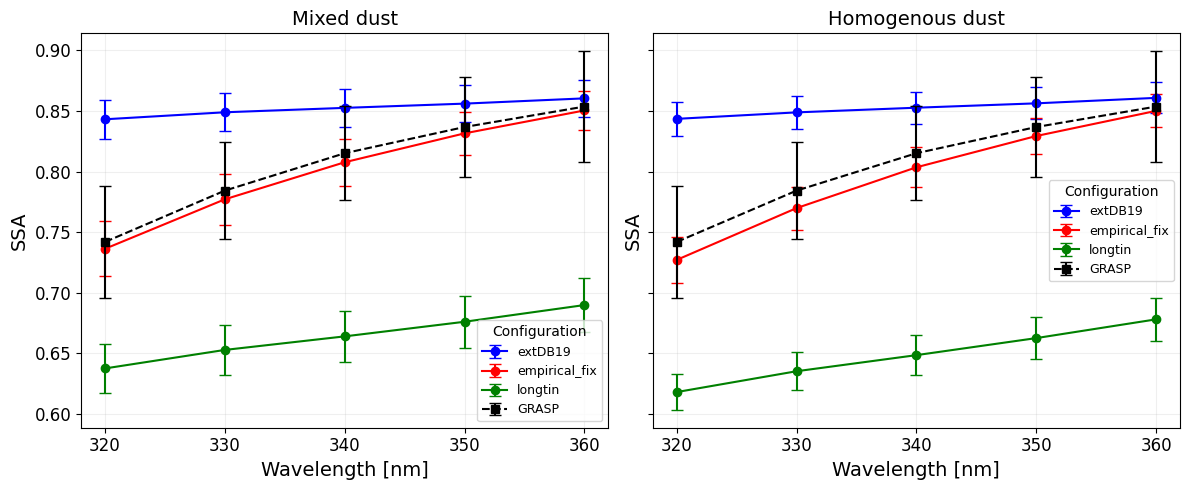

In [16]:
# PLOT OPTIONS
WEIGHT_BY_DOD = False   # True: weighted | False: unweighted
DOD_THRESHOLD = 0.2     # Minimum DOD to include

dod_data = ds_weights["dod_550nm"].to_series()
dod_data.index = pd.to_datetime(dod_data.index)

def plot_dust(ax, dust_type):
    suffixes = ['extDB19', 'empirical_fix', 'longtin']
    colors = {'extDB19': 'blue', 'empirical_fix': 'red', 'longtin': 'green'}

    for suffix in suffixes:
        filepath = os.path.join(results_dir, f'{dust_type}_{suffix}.nc')

        if not os.path.exists(filepath):
            continue

        data = nc_to_df(filepath, "UV")
        ds_results = xr.open_dataset(filepath)
        data.index = pd.to_datetime(ds_results.Day.values)

        common_dates = data.index.intersection(dod_data.index)
        data = data.loc[common_dates]
        dod = dod_data.loc[common_dates]

        valid = dod.notna() & (dod >= DOD_THRESHOLD) & data[ssa_cols[:5]].notna().all(axis=1)
        data, dod = data.loc[valid], dod.loc[valid]

        weights = dod.values / dod.sum() if WEIGHT_BY_DOD else np.ones(len(dod)) / len(dod)

        values = data[ssa_cols[:5]].values
        mean = np.average(values, axis=0, weights=weights)
        std = np.sqrt(np.average((values - mean)**2, axis=0, weights=weights))

        ax.errorbar(WL_uv, mean, yerr=std, fmt='o-', color=colors[suffix], capsize=4, label=suffix)

    ax.errorbar(WL_uv, grasp[ssa_cols[:5]].mean().values, yerr=grasp[ssa_cols[:5]].std().values,
                fmt='s--', color='black', capsize=4, label='GRASP', zorder=5)

    ax.set(title=dust_type.replace('_', ' ').capitalize(),xlabel='Wavelength [nm]',ylabel='SSA',xticks=WL_uv)
    ax.grid(alpha=0.2)
    ax.legend(title='Configuration', fontsize=9, loc='best')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
plot_dust(axes[0], 'mixed_dust')
plot_dust(axes[1], 'homogenous_dust')
fig.tight_layout()
plt.show()

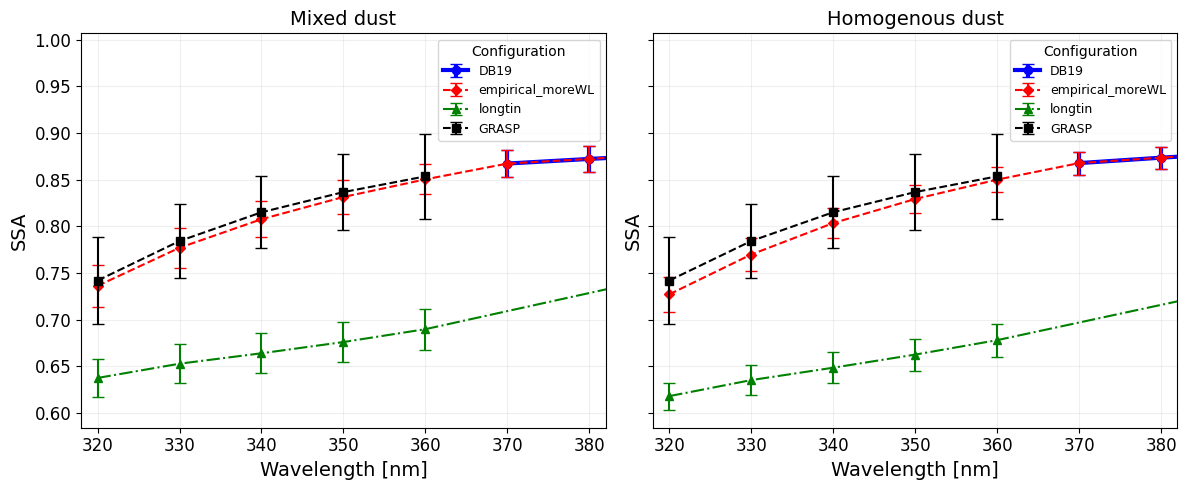

In [17]:
# PLOT OPTIONS
WEIGHT_BY_DOD = False
DOD_THRESHOLD = 0.2
WL_MIN, WL_MAX, WL_STEP = 320, 380, 10

dod_data = ds_weights["dod_550nm"].to_series()
dod_data.index = pd.to_datetime(dod_data.index)

def plot_dust(ax, dust_type):
    suffixes = ['DB19', 'empirical_moreWL', 'longtin']
    colors = {'DB19': 'blue', 'empirical_moreWL': 'red', 'longtin': 'green'}
    styles = {
        'DB19': {'marker': 'o', 'linestyle': '-', 'markersize': 6, 'linewidth': 3},
        'empirical_moreWL': {'marker': 'D', 'linestyle': '--', 'markersize': 5},
        'longtin': {'marker': '^', 'linestyle': '-.', 'markersize': 6}
    }

    for suffix in suffixes:
        filepath = os.path.join(results_dir, f'{dust_type}_{suffix}.nc')
        if not os.path.exists(filepath):
            continue

        if suffix == 'DB19':
            data = nc_to_df_DB19(filepath)
        elif suffix == 'empirical_moreWL':
            data = nc_to_df_extended(filepath)
        else:
            data = nc_to_df(filepath, "UVIS")

        ds_results = xr.open_dataset(filepath)
        data.index = pd.to_datetime(ds_results.Day.values if 'Day' in ds_results else data['date'])
        ds_results.close()

        cols = [c for c in data.columns if c.startswith('SSA_')]
        wvl = np.array([float(c.split('_')[-1]) * (1000 if suffix in ['DB19', 'empirical_moreWL'] else 1) for c in cols])

        common = data.index.intersection(dod_data.index)
        data, dod = data.loc[common], dod_data.loc[common]

        means, stds = [], []
        for col in cols:
            valid = dod.notna() & (dod >= DOD_THRESHOLD) & data[col].notna()
            v, d = data.loc[valid, col].values, dod.loc[valid].values

            if len(v) == 0:
                means.append(np.nan)
                stds.append(np.nan)
                continue

            weights = d / d.sum() if WEIGHT_BY_DOD else np.ones(len(v)) / len(v)
            mean = np.average(v, weights=weights)
            means.append(mean)
            stds.append(np.sqrt(np.average((v - mean)**2, weights=weights)))

        order = np.argsort(wvl)
        ax.errorbar(wvl[order], np.array(means)[order], yerr=np.array(stds)[order],
                    color=colors[suffix], capsize=4, label=suffix, **styles[suffix])

    cols = [c for c in grasp.columns if c.startswith('SSA_')]
    wvl = np.array([float(c.split('_')[-1]) for c in cols])
    order = np.argsort(wvl)

    ax.errorbar(wvl[order], grasp[cols].mean().values[order], yerr=grasp[cols].std().values[order],
                fmt='s--', color='black', capsize=4, label='GRASP', zorder=5)

    ax.set(title=dust_type.replace('_', ' ').capitalize(),
           xlabel='Wavelength [nm]', ylabel='SSA',
           xlim=(WL_MIN-2, WL_MAX+2), xticks=np.arange(WL_MIN, WL_MAX + 1, WL_STEP))
    ax.grid(alpha=0.2)
    ax.legend(title='Configuration', fontsize=9, loc='best')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
plot_dust(axes[0], 'mixed_dust')
plot_dust(axes[1], 'homogenous_dust')
fig.tight_layout()
plt.show()

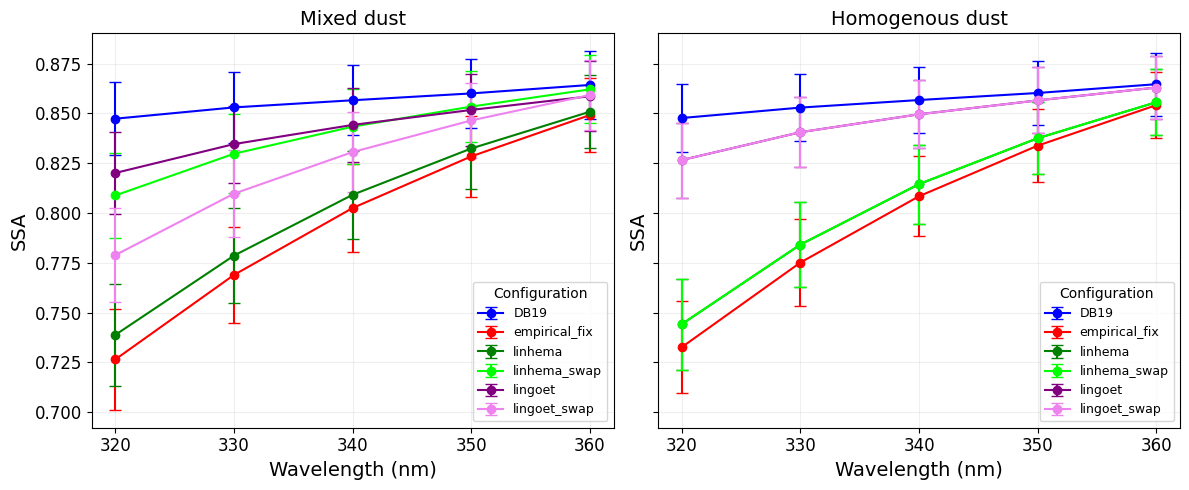

In [19]:
results_dir = "results_hema_goet"
weights_file = "MONARCH_EMIT_data/monarch_massfract_Thess_dod01.nc"

ds_weights = xr.open_dataset(weights_file).sortby("Day")

def plot_dust(ax, dust_type):
    suffixes = ['DB19', 'empirical_fix', 'linhema', 'linhema_swap', 'lingoet', 'lingoet_swap']
    colors = {'DB19': 'blue', 'empirical_fix': 'red', 'linhema': 'green', 'linhema_swap': 'lime', 'lingoet': 'purple', 'lingoet_swap': 'violet'}

    for suffix in suffixes:
        filepath = os.path.join(results_dir, f'{dust_type}_{suffix}.nc')
        if not os.path.exists(filepath):
            continue

        data = nc_to_df(filepath, "UV")
        ds_results = xr.open_dataset(filepath)
        data.index = pd.to_datetime(ds_results.Day.values)
        dod_data = ds_weights["dod_550nm"].to_series()
        dod_data.index = pd.to_datetime(dod_data.index)

        common_dates = data.index.intersection(dod_data.index)
        data = data.loc[common_dates]
        dod = dod_data.loc[common_dates].values

        weights = dod / dod.sum()

        mean = np.average(data[ssa_cols[:5]], axis=0, weights=weights)
        std = np.sqrt(np.average((data[ssa_cols[:5]] - mean)**2, axis=0, weights=weights))

        ax.errorbar(WL_uv, mean, yerr=std, fmt='o-', color=colors[suffix], capsize=4, label=suffix)

    #ax.errorbar(WL_uv, grasp[ssa_cols[:5]].mean().values, yerr=grasp[ssa_cols[:5]].std().values, fmt='s--', color='black', capsize=4, label='GRASP', zorder=5)

    ax.set(title=dust_type.replace('_', ' ').capitalize(), xlabel='Wavelength (nm)', ylabel='SSA', xticks=WL_uv)
    ax.grid(alpha=0.2)
    ax.legend(title='Configuration', fontsize=9, loc='best')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
plot_dust(axes[0], 'mixed_dust')
plot_dust(axes[1], 'homogenous_dust')
fig.tight_layout()
plt.show()

Jethva et al., 2026 SSA at 4 UV wvls for IZO:

In [21]:
jethva = pd.DataFrame({
    "datetime": ["2020-08-26", "2020-08-27", "2020-08-28"],
    "SSA_380": [0.851, 0.857, 0.856],
    "SSA_340": [0.813, 0.820, 0.823],
    "SSA_332": [0.807, 0.819, 0.821],
    "SSA_325": [0.800, 0.823, 0.822]
})

jethva.loc[len(jethva)] = ["average"] + jethva.iloc[:, 1:].mean().tolist()
print(jethva)


     datetime   SSA_380   SSA_340   SSA_332  SSA_325
0  2020-08-26  0.851000  0.813000  0.807000    0.800
1  2020-08-27  0.857000  0.820000  0.819000    0.823
2  2020-08-28  0.856000  0.823000  0.821000    0.822
3     average  0.854667  0.818667  0.815667    0.815


In [22]:
results_dir = "results_IrOx"
weights_file = "monarch_massfract_IZO_dod01.nc"

ds_weights = xr.open_dataset(weights_file).sortby("Day")

def plot_dust(ax, dust_type):
    suffixes = ['IZO_DB19', 'IZO_empirical_fix']
    colors = {'IZO_DB19': 'blue', 'IZO_empirical_fix': 'red'}

    for suffix in suffixes:
        filepath = os.path.join(results_dir, f'{dust_type}_{suffix}.nc')

        if not os.path.exists(filepath):
            continue

        data = nc_to_df(filepath, "UV")
        ds_results = xr.open_dataset(filepath)

        data.index = pd.to_datetime(ds_results.Day.values)

        dod_data = ds_weights["dod_550nm"].to_series()
        dod_data.index = pd.to_datetime(dod_data.index)

        common_dates = data.index.intersection(dod_data.index)
        data = data.loc[common_dates]
        dod = dod_data.loc[common_dates].values

        if len(dod) == 0 or dod.sum() == 0:
            print(f'{dust_type}_{suffix}: No matching DOD values')
            continue

        weights = dod / dod.sum()

        mean = np.average(data[ssa_cols[:5]], axis=0, weights=weights)
        std = np.sqrt(np.average((data[ssa_cols[:5]] - mean)**2, axis=0, weights=weights))

        ax.errorbar(WL_uv, mean, yerr=std, fmt='o-', color=colors[suffix],
                    capsize=4, label=suffix)
        
    jethva_wvl = [325, 332, 340, 380]
    jethva_cols = [f"SSA_{wl}" for wl in jethva_wvl]
    jethva_avg = jethva.loc[jethva["datetime"] == "average", jethva_cols].iloc[0].values
    ax.plot(jethva_wvl, jethva_avg, 'o-', color='green', label='Jethva et al. (2026)')

    ax.set(title=dust_type.replace('_', ' ').capitalize(), xlabel='Wavelength (nm)', ylabel='SSA', xticks=sorted(set(WL_uv.tolist() + [380])))
    ax.grid(alpha=0.2)
    ax.legend(title='Configuration', fontsize=9, loc='best')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
plot_dust(axes[0], 'mixed_dust')
plot_dust(axes[1], 'homogenous_dust')
fig.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Usuario\\Desktop\\GitHub_Laptop\\BSC_Secondment\\monarch_massfract_IZO_dod01.nc'

#### Complete plots (aeronet and so on): Files selection (to plot)

In [23]:
# Get all NetCDF files
nc_files = glob.glob(os.path.join(results_dir, "*.nc"))

# Organize files by dust type and experiment number
mixed_files = {}
homogenous_files = {}
mixed_original = nc_to_df(os.path.join(results_dir, "mixed_dust_DB19.nc"), range="UVIS")
homo_original = nc_to_df(os.path.join(results_dir, "homogenous_dust_DB19.nc"), range="UVIS")

mixed_dust_longtin = nc_to_df(os.path.join(results_dir, "mixed_dust_longtin.nc"), range="UVIS")
homo_longtin = nc_to_df(os.path.join(results_dir, "homogenous_dust_longtin.nc"), range="UVIS")
mixed_dust_empirical = nc_to_df(os.path.join(results_dir, "mixed_dust_empirical_fix.nc"), range="UVIS")
homo_empirical = nc_to_df(os.path.join(results_dir, "homogenous_dust_empirical_fix.nc"), range="UVIS")


In [24]:
def calculate_ssa_stats(files):
    results = {}
    for exp, file in sorted(files.items()):
        df = nc_to_df(file, range="UVIS")
        results[exp] = {'mean': df[ssa_cols].mean().values, 'std': df[ssa_cols].std().values}
    return results

mixed_stats = calculate_ssa_stats(mixed_files)
homogenous_stats = calculate_ssa_stats(homogenous_files)

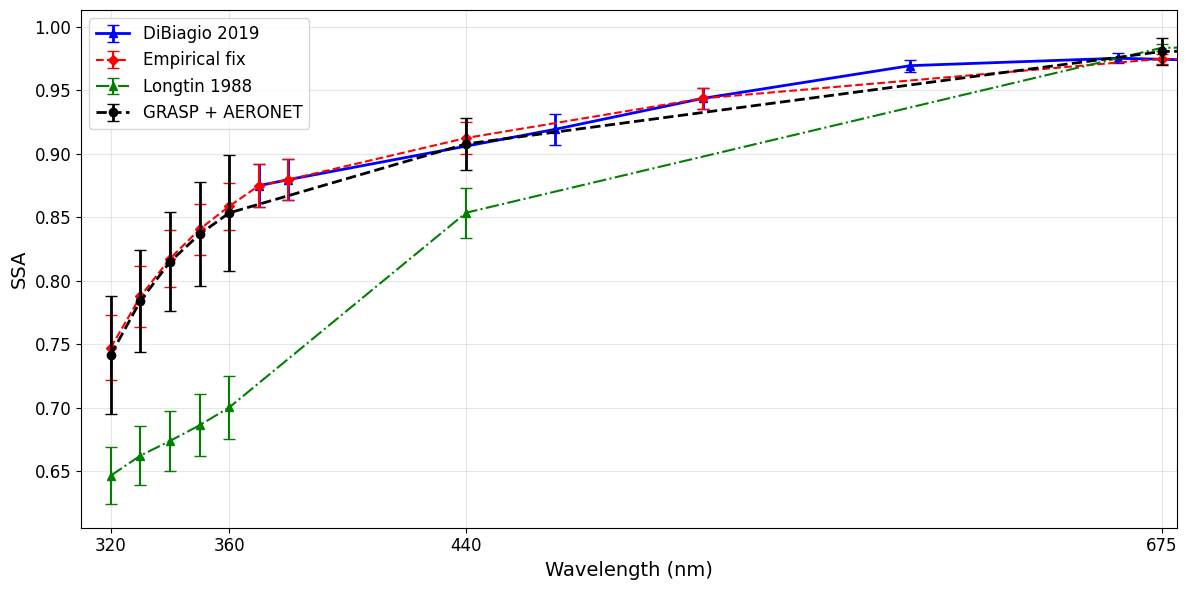

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))

suffixes = ['DB19', 'empirical_moreWL', 'longtin']
colors = {'DB19': 'blue', 'empirical_moreWL': 'red', 'longtin': 'green'}
labels = {'DB19': 'DiBiagio 2019', 'empirical_moreWL': 'Empirical fix', 'longtin': 'Longtin 1988'}
styles = {
    'DB19': {'marker': '^', 'linestyle': '-', 'markersize': 6, 'linewidth': 2},
    'empirical_moreWL': {'marker': 'D', 'linestyle': '--', 'markersize': 5, 'linewidth': 1.5},
    'longtin': {'marker': '^', 'linestyle': '-.', 'markersize': 6, 'linewidth': 1.5}
}

for suffix in suffixes:
    filepath = os.path.join(results_dir, f'mixed_dust_{suffix}.nc')
    if not os.path.exists(filepath):
        continue

    if suffix == 'DB19':
        data = nc_to_df_DB19(filepath)
    elif suffix == 'empirical_moreWL':
        data = nc_to_df_extended(filepath)
    else:
        data = nc_to_df(filepath, "UVIS")

    ds_results = xr.open_dataset(filepath)
    data.index = pd.to_datetime(ds_results.Day.values if 'Day' in ds_results else data['date'])
    ds_results.close()

    cols = [c for c in data.columns if c.startswith('SSA_')]
    wvl = np.array([float(c.split('_')[-1]) * (1000 if suffix in ['DB19', 'empirical_moreWL'] else 1) for c in cols])
    order = np.argsort(wvl)

    ax.errorbar(wvl[order], data[cols].mean().values[order], yerr=data[cols].std().values[order],
                color=colors[suffix], capsize=4, label=labels[suffix], zorder=9, **styles[suffix])

ax.errorbar(WL_all, mean_all, yerr=std_all, fmt='--', marker='o', color='black',
            capsize=4, markersize=6, linewidth=2, label='GRASP + AERONET', zorder=10)

ax.set(xticks=[320, 360, 440, 675, 870], ylabel='SSA', xlabel='Wavelength (nm)')
ax.set_xlim(310, 680)
ax.grid(alpha=0.3)
ax.legend(loc='best')

plt.tight_layout()
plt.show()

### Sensitivity tests

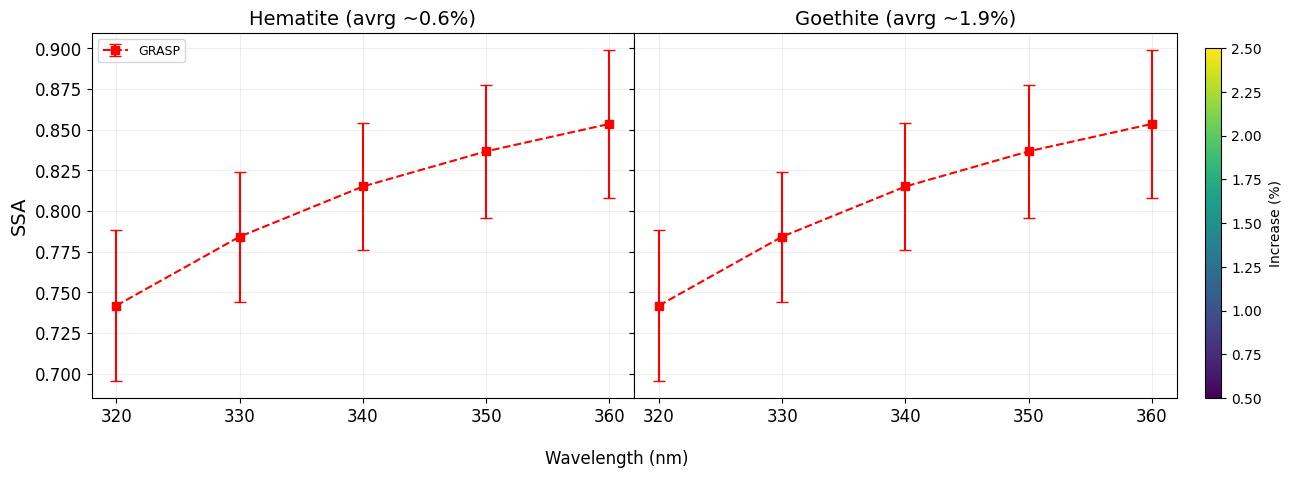

In [ ]:
#Sensitivity to increase in IrOx species mass fractions
results_dir = "results_IrOx_sens"
norm = mpl.colors.Normalize(vmin=0.5, vmax=2.5)
cmap = plt.cm.viridis

def plot_mineral(ax, mineral):
    files = glob.glob(os.path.join(results_dir, f'mixed_dust*{mineral}_[1-5].nc'))

    for filepath in sorted(files):
        match = re.search(rf'{mineral}_([1-5])\.nc$', os.path.basename(filepath))
        if not match:
            continue

        step = int(match.group(1))
        increase = step * 0.5
        color = cmap(norm(increase))

        data = nc_to_df(filepath, "UV")
        mean = data[ssa_cols[:5]].mean().values
        std = data[ssa_cols[:5]].std().values

        ax.errorbar(WL_uv, mean, yerr=std, fmt='o-', color=color,capsize=4, markersize=4, linewidth=1.3, zorder=2)

    ax.errorbar(WL_uv, grasp[ssa_cols[:5]].mean().values, yerr=grasp[ssa_cols[:5]].std().values, fmt='s--', color='red', capsize=4, label='GRASP', zorder=5)
    ax.set(xticks=WL_uv)

    for suffix, color, label, fmt in [('base', 'black', 'Base', '-.'),('swap', 'orange', 'Swap', '-.')]:
        files_extra = glob.glob(os.path.join(results_dir, f'mixed_dust_{suffix}.nc'))

        for filepath in files_extra:
            data = nc_to_df(filepath, "UV")
            ax.errorbar(WL_uv, data[ssa_cols[:5]].mean().values,yerr=data[ssa_cols[:5]].std().values, fmt=fmt, color=color, capsize=4,
                        markersize=4, linewidth=1.3, label=label, zorder=4)
    ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
fig.subplots_adjust(right=0.90, wspace=0, bottom=0.15)

plot_mineral(axes[0], 'hema')
plot_mineral(axes[1], 'goet')

axes[0].set_title('Hematite (avrg ~0.6%)')
axes[1].set_title('Goethite (avrg ~1.9%)')
axes[0].set_ylabel('SSA')

fig.supxlabel('Wavelength (nm)')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar_ax = fig.add_axes([0.92, 0.15, 0.012, 0.70])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Increase (%)', fontsize=10, labelpad=5)
cbar.ax.tick_params(labelsize=10)

axes[0].legend(fontsize=9, loc='best')

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Usuario\\Desktop\\BSC_secondment\\vobiso\\miguel_optical_package\\results_IrOx_sens\\mixed_dust_base.nc'

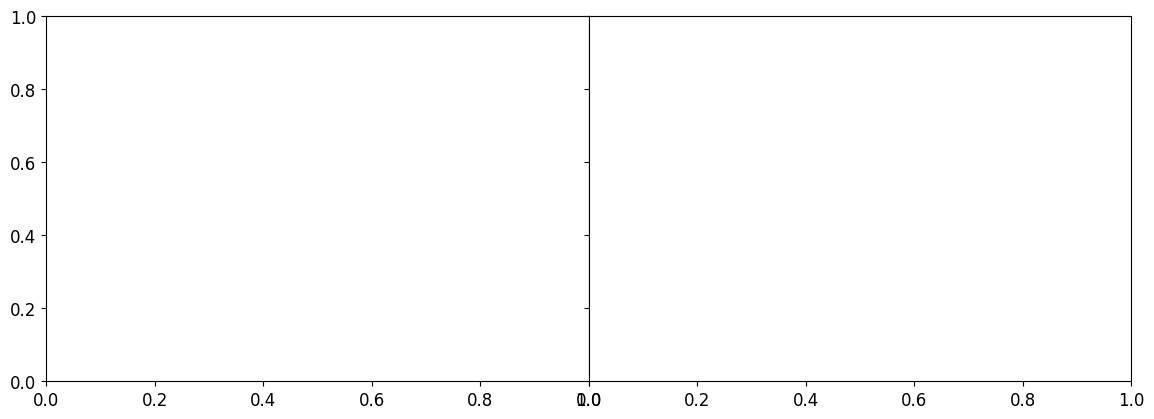

In [27]:
def plot_mineral(ax, mineral):
    grasp_mean = grasp[ssa_cols[:5]].mean().values

    files = glob.glob(os.path.join(results_dir, f'mixed_dust*{mineral}_[1-5].nc'))

    for filepath in sorted(files):
        match = re.search(rf'{mineral}_([1-5])\.nc$', os.path.basename(filepath))
        if not match:
            continue

        step = int(match.group(1))
        increase = step * 0.5
        color = cmap(norm(increase))

        data = nc_to_df(filepath, "UV")
        mean = data[ssa_cols[:5]].mean().values
        std = data[ssa_cols[:5]].std().values

        ax.errorbar(WL_uv, mean - grasp_mean, yerr=std, fmt='o-', color=color, capsize=4, markersize=4, linewidth=1.3, zorder=2)

    for suffix, color, label, fmt in [('base', 'black', 'Base', '^-'), ('swap', 'orange', 'Swap', 'D-')]:
        filepath = os.path.join(results_dir, f'mixed_dust_{suffix}.nc')
        data = nc_to_df(filepath, "UV")
        ax.errorbar(WL_uv, data[ssa_cols[:5]].mean().values - grasp_mean, yerr=data[ssa_cols[:5]].std().values, fmt=fmt, color=color, capsize=4, markersize=4, linewidth=1.3, label=label, zorder=4)

    ax.axhline(0, color='red', linestyle='--', linewidth=1, zorder=1)
    ax.set(xticks=WL_uv)
    ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
fig.subplots_adjust(right=0.90, wspace=0, bottom=0.15)

plot_mineral(axes[0], 'hema')
plot_mineral(axes[1], 'goet')

axes[0].set_title('Hematite (avrg ~0.6%)')
axes[1].set_title('Goethite (avrg ~1.9%)')
axes[0].set_ylabel('delta SSA')

fig.supxlabel('Wavelength (nm)')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar_ax = fig.add_axes([0.92, 0.15, 0.012, 0.70])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Increase (%)', fontsize=10, labelpad=5)
cbar.ax.tick_params(labelsize=10)

axes[0].legend(fontsize=9, loc='best')

plt.show()

##################################################################################

In [ ]:
file = r'C:/Users/Usuario/Desktop/BSC_secondment/vobiso/miguel_optical_package/results/homogenous_dust.nc' # homogenous_dust
opt_results = nc_to_df(file)

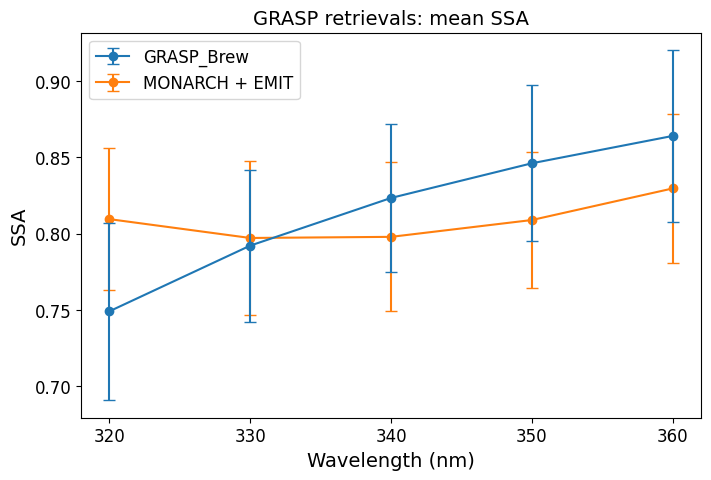

In [ ]:
plt.figure(figsize=(8,5))

plt.errorbar(WL_uv, ssa_mean, yerr=ssa_std, fmt='o-', capsize=4, label="GRASP_Brew", zorder=3) #label="multipixel", 
plt.errorbar(WL_uv, SSA_mean, yerr=SSA_std, fmt='o-', capsize=4, label="MONARCH + EMIT", zorder=2) #label="single-pixel", 


plt.xlabel("Wavelength (nm)")
plt.ylabel("SSA")
plt.title("GRASP retrievals: mean SSA")
plt.xticks(WL_uv)
#plt.yticks(np.arange(0.7, 0.925, 0.025))
plt.legend()
plt.show()

In [ ]:
daily_counts = grasp.groupby(grasp["datetime"].dt.floor("D")).size()
 
for d, count in daily_counts.items():
    print(d.year, ", doy:", d.dayofyear, ", retrievals:", count)

2014 , doy: 176 , retrievals: 5
2014 , doy: 177 , retrievals: 6
2016 , doy: 134 , retrievals: 4
2016 , doy: 169 , retrievals: 6
2016 , doy: 170 , retrievals: 10
2016 , doy: 172 , retrievals: 6
2016 , doy: 173 , retrievals: 7
2017 , doy: 182 , retrievals: 7
2017 , doy: 183 , retrievals: 12
2018 , doy: 76 , retrievals: 5
2018 , doy: 121 , retrievals: 9
2021 , doy: 214 , retrievals: 4
2022 , doy: 91 , retrievals: 4
2022 , doy: 174 , retrievals: 4
2023 , doy: 203 , retrievals: 9
2023 , doy: 265 , retrievals: 8
2023 , doy: 266 , retrievals: 7


In [ ]:
doy = 167
year = 2010
tperiod = grasp.loc[(grasp["datetime"].dt.year==year)&(grasp["datetime"].dt.day_of_year==doy)] 
aod_day = data.loc[(data["datetime"].dt.year == year) & (data["datetime"].dt.day_of_year == doy)]
monarch_day= opt_results.loc[(opt_results["date"].dt.year==year)&(opt_results["date"].dt.day_of_year==doy)] 
monarch_day["AOD_340"]

14    0.033347
Name: AOD_340, dtype: float32

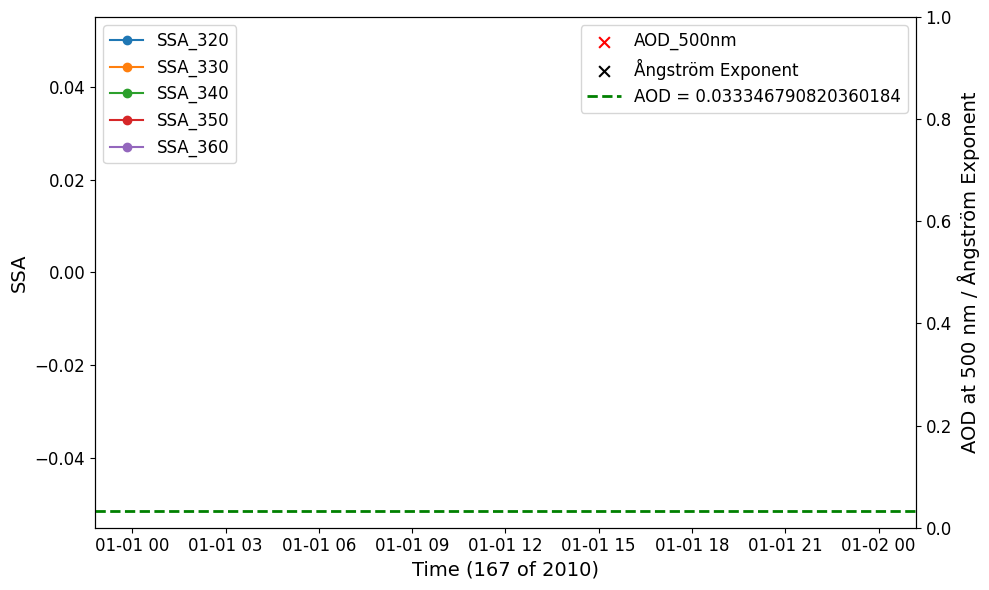

In [ ]:
aod_value = monarch_day["AOD_340"].iloc[0]

plt.figure(figsize=(10,6))
ax1 = plt.gca()
for i in range(len(WL_uv)):
    wavelength = ssa_cols[i]
    ax1.plot(tperiod["datetime"],tperiod[wavelength], label=wavelength, marker='o')
ax1.set_xlabel(f"Time ({doy} of {year})")
ax1.set_ylabel('SSA')
ax2 = ax1.twinx()
ax2.scatter(aod_day["datetime"],aod_day["AOD_500nm"], color='red', marker='x', s=60, label='AOD_500nm')
ax2.scatter(aod_day["datetime"],aod_day["440-870_Angstrom_Exponent"], color='black', marker='x', s=60, label='Ångström Exponent')
ax2.axhline(y=aod_value, color='green', linestyle='--', linewidth=2, label=f'AOD = {aod_value}')
ax2.set_ylabel('AOD at 500 nm / Ångström Exponent')
ax2.tick_params(axis='y')
ax2.set_ylim([0.0, 1.0])
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()